# Ray-traced wireless channels

Adapted from NVIDIA’s [Sionna, v2.2.0](https://nvlabs.github.io/sionna/index.html).

## Basics and imports

Ray tracing is a technique to simulate environment-specific and physically accurate channel realizations for a given scene and user position.

Sionna RT is a open-source hardware-accelerated differentiable ray tracer for radio propagation modeling which is built on top of [Mitsuba 3](https://www.mitsuba-renderer.org/). Mitsuba 3 is a rendering system for forward and inverse light-transport simulation that makes use of the differentiable just-in-time compiler [Dr.Jit](https://drjit.readthedocs.io/en/latest/).

Sionna RT relies on Mitsuba 3 for the rendering and handling of scenes, e.g., its XML-file format.
When imported, Sionna RT automatically configures the correct [Mitsuba variant](https://mitsuba.readthedocs.io/en/stable/src/key_topics/variants.html) based on the available hardware.

In [1]:
# Import sionna and some of its relevant components
import sionna.rt
from sionna.rt import load_scene, PlanarArray, Transmitter, Receiver, Camera, PathSolver

# Import packages for this notebook to work
%matplotlib inline
import matplotlib.pyplot as plt
import mitsuba as mi
import numpy as np
from pathlib import Path

no_preview = False # Toggle to False to use the preview widget

# Query the Mitsuba variant that was automatically selected by Sionna RT.
# There should be no need to adjust it, but if you do, make sure to select
# a variant ending in `*_ad_mono_polarized`.
print(f"Mitsuba variant: {mi.variant()}")

Mitsuba variant: cuda_ad_mono_polarized


## Loading and Visualizing Scenes

Sionna RT can either load external scene files (in Mitsuba's XML file format) or it can load one of the [integrated scenes](https://nvlabs.github.io/sionna/rt/api/scene.html#examples).

In this example, we load an example scene containing central Florence, Italy.

In [2]:
# Load the integrated Florence scene
carrier_frequency = 3e9  # Hz
scene_florence = load_scene(sionna.rt.scene.florence, merge_shapes=True)
scene_florence.frequency = carrier_frequency

To visualize the scene, we can use the `preview` function which opens an interactive preview of the scene.
This only works in Jupyter notebooks.

You can use the following controls:

- Mouse left: Rotate
- Scroll wheel: Zoom
- Mouse right: Move
- Alt+Click: select a point to retrieve coordinates

Please note that only one preview instance per scene can be opened at the same time.
However, multiple scenes can be loaded in parallel.

In [3]:
if not no_preview:
    scene_florence.preview();

It is often convenient to choose a viewpoint in the 3D preview prior to rendering it as a high-quality image.
The next cell uses the "preview" camera which corresponds to the viewpoint of the current preview image.

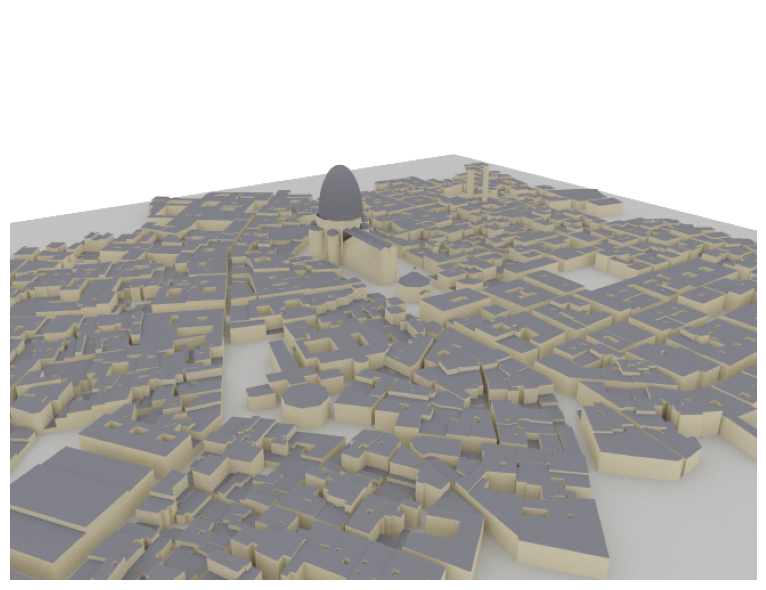

In [5]:
# Only available if a preview is open
if not no_preview:
    scene_florence.render(camera="preview", num_samples=512);

Instead of the preview camera, one can also specify dedicated cameras with different positions and `look_at` directions.

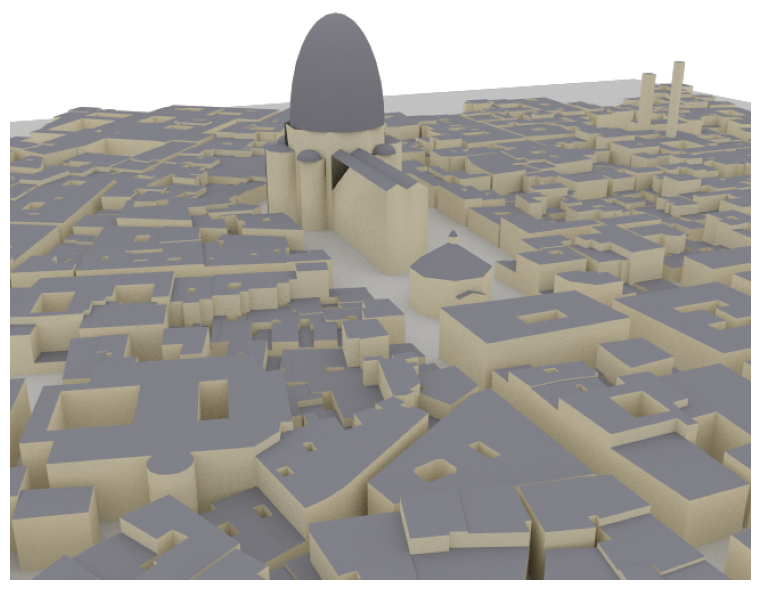

In [6]:
# Create new camera with different configuration
my_cam = Camera(position=[-350,150,150], look_at=[0,0,0])

# Render scene_florence with new camera*
scene_florence.render(camera=my_cam, resolution=[650, 500], num_samples=512); # Increase num_samples to increase image quality

### Let us try to load a custom Pisa scene

Scene files for Mitsuba 3 can be created, edited, and exported with the popular open-source 3D creation suite [Blender](https://www.blender.org/) and the [Mitsuba-Blender add-on](https://github.com/mitsuba-renderer/mitsuba-blender). One can rapdily create scenes from almost any place in the world using [OpenStreetMap](https://www.openstreetmap.org/) and the [Blender-OSM add-on](https://prochitecture.gumroad.com/l/blender-osm). In Sionna, scenes and radio propagation paths can be either rendered through the lens of configurable cameras via ray tracing or displayed with an integrated 3D viewer. For more detail on scene creation and rendering, we refer to [Sionna RT's API documentation](https://nvlabs.github.io/sionna/rt/api/rt.html) and the available [video tutorial](https://youtu.be/7xHLDxUaQ7c).

Set `pisa_scene_file` to the XML file exported from Blender/Mitsuba that is in `scenes` subfolder. Then, write the small piece of code below to preview the Pisa scene, move the camera in a desired position and render the image.

In [7]:
pisa_scene_file = None
scene_pisa = None
if pisa_scene_file is not None:
    pisa_scene_file = Path(pisa_scene_file)
    if not pisa_scene_file.is_file():
        raise FileNotFoundError(pisa_scene_file)
    scene_pisa = load_scene(str(pisa_scene_file), merge_shapes=True)
    scene_pisa.frequency = carrier_frequency
else:
    print("Pisa scene not configured; continuing with Florence.")

Pisa scene not configured; continuing with Florence.


## Ray tracing of Propagation Paths

Once a scene is loaded, we can place Transmitters and Receivers in it and compute propagation paths between them.
All transmitters and all receivers are equipped with the same antenna arrays which are defined by the scene properties `scene_florence.tx_array` and `scene_florence.rx_array`, respectively. Antenna arrays are composed of multiple identical antennas. Antennas can have custom or pre-defined patterns and are either single- or dual-polarized. A scene can contain multiple transmitters and receivers as long as they have unique names.

More details on antenna patterns can be found in the Developer Guide [Understanding Radio Materials](https://nvlabs.github.io/sionna/rt/developer/dev_custom_radio_materials.html).

In [8]:
# Configure the Florence link (coordinates in metres).
# Configure antenna array for all transmitters
scene_florence.tx_array = PlanarArray(num_rows=1,
                             num_cols=1,
                             vertical_spacing=0.5,
                             horizontal_spacing=0.5,
                             pattern="tr38901",
                             polarization="V")

# Configure antenna array for all receivers
scene_florence.rx_array = PlanarArray(num_rows=1,
                             num_cols=1,
                             vertical_spacing=0.5,
                             horizontal_spacing=0.5,
                             pattern="dipole",
                             polarization="V")

# Create transmitter
tx = Transmitter(name="tx",
                 position=[-22,-23,35],
                 display_radius=2)

# Add transmitter instance to scene_florence
scene_florence.add(tx)

# Create a receiver
rx = Receiver(name="rx",
              position=[44,-2,1.5],
              display_radius=2)

# Add receiver instance to scene_florence
scene_florence.add(rx)

tx.look_at(rx) # Transmitter points towards receiver

Propagation paths are computed with the help of a [PathSolver](https://nvlabs.github.io/sionna/rt/api/paths_solvers.html).
The next cell shows how such a path solver is instantiated and used. 

The parameter `max_depth` determines the maximum number of interactions between a ray and a scene objects. 
For example, with a `max_depth` of zero, only LoS paths are considered. For a `max_depth` of one, LoS as well as first-order reflections of refractions are considered.  When the argument `synthetic_array` is set to `False`, antenna arrays are explicitly modeled by finding paths between any pair of transmitting and receiving antennas in the scene. Otherwise, arrays are represented by a single antenna located in the center of the array and phase shifts related to the relative antenna positions are applied based on a plane-wave assumption.

In [9]:
# Instantiate a path solver
# The same path solver can be used with multiple scenes
p_solver  = PathSolver()

# Compute propagation paths
paths = p_solver(scene=scene_florence,
                 max_depth=5,
                 los=True,
                 specular_reflection=True,
                 diffuse_reflection=False,
                 refraction=True,
                 synthetic_array=False,
                 seed=41)

The [Paths](https://nvlabs.github.io/sionna/rt/paths.html) object contains all paths that have been found between transmitters and receivers.
In principle, the existence of each path is deterministic for a given position and environment. By default, however, `PathSolver` does not guarantee deterministic results, even when `seed` is fixed. Use `PathSolver(deterministic=True)` when deterministic results are required.

Let us now visualize the found paths in the scene:

In [10]:
if no_preview:
    scene_florence.render(camera=my_cam, paths=paths, clip_at=100);
else:
    scene_florence.preview(paths=paths, clip_at=100);

The Paths object contains detailed information about every found path and allows us to generate channel impulse responses and apply Doppler shifts for the simulation of time evolution.

### Trace the custom Pisa scene

The same `p_solver` instance can trace a different scene. Fill in the following code setting tx and rx arrays, position of transmitter and receiver and generate the paths as `paths_pisa`. Visualize the scene.

In [11]:
paths_pisa = None
pisa_tx_position = None  # TODO: [x, y, z] in metres in the custom scene
pisa_rx_position = None  # TODO: [x, y, z] in metres in the custom scene

if scene_pisa is None:
    print("Skipping Pisa ray tracing: load the custom scene first.")
elif pisa_tx_position is None or pisa_rx_position is None:
    print("Set pisa_tx_position and pisa_rx_position, then rerun this cell.")
else:
    scene_pisa.tx_array = PlanarArray(num_rows=1, num_cols=1,
        vertical_spacing=0.5, horizontal_spacing=0.5,
        pattern="tr38901", polarization="V")
    scene_pisa.rx_array = PlanarArray(num_rows=1, num_cols=1,
        vertical_spacing=0.5, horizontal_spacing=0.5,
        pattern="dipole", polarization="cross")
    # Re-running this cell replaces the previously configured devices.
    scene_pisa.remove("tx")
    scene_pisa.remove("rx")
    tx_pisa = Transmitter(name="tx", position=pisa_tx_position, display_radius=2)
    rx_pisa = Receiver(name="rx", position=pisa_rx_position, display_radius=2)
    scene_pisa.add(tx_pisa)
    scene_pisa.add(rx_pisa)
    tx_pisa.look_at(rx_pisa)
    paths_pisa = p_solver(scene=scene_pisa,
        max_depth=5, los=True, specular_reflection=True,
        diffuse_reflection=False, refraction=True,
        synthetic_array=False, seed=41)
    if not no_preview:
        scene_pisa.preview(paths=paths_pisa)


Skipping Pisa ray tracing: load the custom scene first.


Now create a custom `p_solver_test` instantiating the PathSolver() and try to vary the parameters of the solver. For example, you can vary the maximum depth of the ray tracing, the presence of specular reflection, the presence of diffuse reflection, the presence of refraction, and the seed of the random number generator. Try a couple of changes and render again the scene every time. Do you see changes in the tracer?

In [12]:
# Instantiate a path solver
# The same path solver can be used with multiple scenes
p_solver_test  = PathSolver()

if scene_pisa:
    scene_test = scene_pisa
else:
    scene_test = scene_florence

# Compute propagation paths
paths_test = p_solver_test(scene=scene_test,
                     max_depth=1,
                     los=True,
                     specular_reflection=True,
                     diffuse_reflection=False,
                     refraction=False,
                     synthetic_array=False,
                     seed=52)

if no_preview:
    scene_test.render(camera=my_cam, paths=paths_test, clip_at=100);
else:
    scene_test.preview(paths=paths_test, clip_at=100);

## From Paths to Channel Impulse and Frequency Responses



Once paths are computed, they can be transformed into a baseband-equivalent channel impulse response (CIR) via [Paths.cir()](https://nvlabs.github.io/sionna/rt/api/paths.html#sionna.rt.Paths.cir), into a discrete complex baseband-equivalent channel impulse response via [Paths.taps()](https://nvlabs.github.io/sionna/rt/api/paths.html#sionna.rt.Paths.taps), or into a channel frequency response (CFR) via
[Paths.cfr()](https://nvlabs.github.io/sionna/rt/api/paths.html#sionna.rt.Paths.cfr). These class methods can simulate time evolution of the channel based on the computed Doppler shifts (see [Paths.doppler](https://nvlabs.github.io/sionna/rt/api/paths.html#sionna.rt.Paths.doppler)).

Let us first derive and visualize the baseband-equivalent channel impulse response from the paths computed above. Using the method `paths.cir`, we can obtain the complex baseband equivalent channel coefficients $a^{\text{b}}_{i}$ and their delays $\tau_i$ [s], where

$$
a^{\text{b}}_{i}(t) = \underbrace{a_{i} e^{-j2 \pi f \tau_{i}}}_{a^{\text{b}}_{i} } \underbrace{e^{j 2\pi f_{\Delta, i} t}}_{\text{Doppler phase shift}}
$$

In [13]:
a, tau = paths.cir(normalize_delays=False, out_type="numpy")

# Shape: [num_rx, num_rx_ant, num_tx, num_tx_ant, num_paths, num_time_steps]
print("Shape of a: ", a.shape)

# Shape: [num_rx, num_rx_ant, num_tx, num_tx_ant, num_paths]
print("Shape of tau: ", tau.shape)

Shape of a:  (1, 1, 1, 1, 30, 1)
Shape of tau:  (1, 1, 1, 1, 30)


If `normalize_delays=True`, the delay of the first arriving path is by default normalized to zero. Let's keep it to `False` for the whole simulation here.
The `out_type` argument can be used to convert the CIR into tensors from different frameworks, such as the widely used [Numpy](https://numpy.org) ("numpy").

Let us try to visualize the the CIR with the following code:

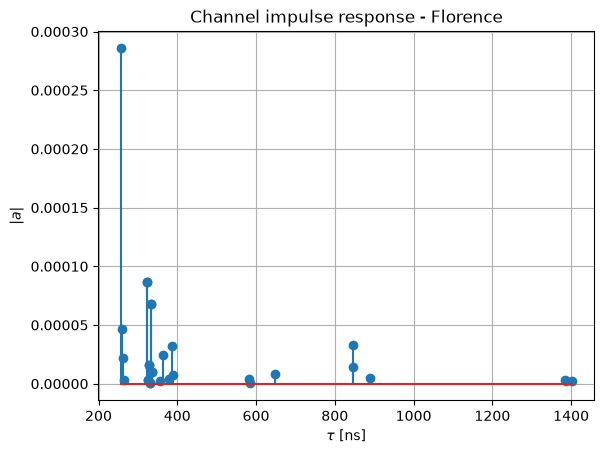

In [14]:
t = tau[0,0,0,0,:]/1e-9 # Scale to ns
a_abs = np.abs(a)[0,0,0,0,:,0]
a_max = np.max(a_abs)

# And plot the CIR
plt.figure()
plt.title("Channel impulse response - Florence")
plt.stem(t, a_abs)
plt.grid()
plt.xlabel(r"$\tau$ [ns]")
plt.ylabel(r"$|a|$");

We can obtain the channel frequency response in a similar manner. `paths,cfr` takes the cir (internally) and returns:
$$
\widehat{h}(f, t) = \sum_{i=0}^{M-1}a_i^\text{b}(t) e^{-j2\pi f \tau_{i}}
$$
Here it is evaluated on a uniformly spaced frequency grid spanning 20 MHz at about 3 GHz. 

Shape of h_freq: (1, 1, 1, 1, 1, 1024)


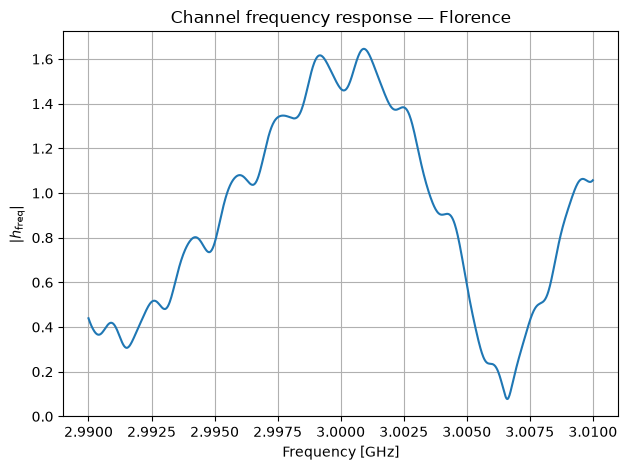

In [15]:
# Frequency sweep: 2.99 to 3.01 GHz, without OFDM parameters
bandwidth = 20e6  # Hz
num_frequencies = 1024
frequencies = np.linspace(-bandwidth/2, bandwidth/2, num_frequencies)
rf_frequencies = carrier_frequency + frequencies

h_freq = paths.cfr(frequencies=frequencies,
                   normalize=True,
                   normalize_delays=False,
                   out_type="numpy")
# Shape: [num_rx, num_rx_ant, num_tx, num_tx_ant, num_time_steps, num_frequencies]
print("Shape of h_freq:", h_freq.shape)

plt.figure()
plt.plot(rf_frequencies/1e9, np.abs(h_freq[0,0,0,0,0,:]))
plt.xlabel("Frequency [GHz]")
plt.ylabel(r"$|h_\mathrm{freq}|$")
plt.title("Channel frequency response — Florence")
plt.grid(True)
plt.tight_layout();


### CFR over time: static paths
Our aim here is to show the time variability of the channel under user mobility (whenever present).

First use the original `paths`, computed with stationary devices and objects.

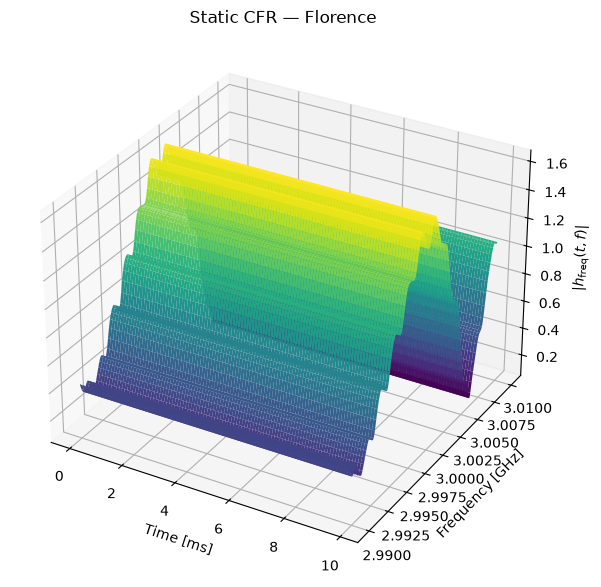

In [16]:
# Static reference: use the original paths without recomputing them.
num_time_steps = 100
sampling_frequency = 1e4  # Hz
h_freq_static = paths.cfr(frequencies=frequencies,
    sampling_frequency=sampling_frequency, num_time_steps=num_time_steps,
    normalize=True, normalize_delays=True, out_type="numpy")

time_ms = np.arange(num_time_steps)/sampling_frequency*1e3
time_grid, frequency_grid = np.meshgrid(time_ms, rf_frequencies/1e9, indexing="ij")

def plot_cfr_surface(h, title):
    fig = plt.figure(figsize=(10, 6))
    ax = fig.add_subplot(111, projection="3d")
    ax.plot_surface(time_grid, frequency_grid, np.abs(h[0,0,0,0,:,:]),
                    cmap="viridis", rcount=100, ccount=128)
    ax.set_xlabel("Time [ms]")
    ax.set_ylabel("Frequency [GHz]")
    ax.set_zlabel(r"$|h_\mathrm{freq}(t,f)|$")
    ax.set_title(title)
    fig.tight_layout()
    plt.show()

plot_cfr_surface(h_freq_static, "Static CFR — Florence")


### CFR over time: mobility paths

Every radio device and scene object has a velocity vector, used to compute path-specific Doppler shifts. Set the transmitter velocity to 10 m/s along x and recompute `paths_mob` using the same solver settings as the static case. The CFR then evolves according to these Doppler shifts, with geometry held at the traced snapshot. See the [Mobility tutorial](https://nvlabs.github.io/sionna/rt/tutorials/Mobility.html).

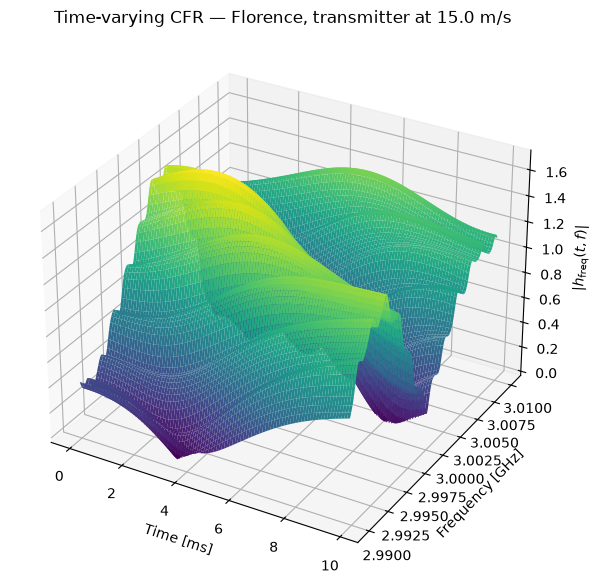

In [17]:
speed = [15, 0, 0]
speed_mag = np.linalg.norm(speed)
scene_florence.get("tx").velocity = speed
try:
    paths_mob = p_solver(scene=scene_florence,
        max_depth=5, los=True, specular_reflection=True,
        diffuse_reflection=False, refraction=True,
        synthetic_array=False, seed=41)
finally:
    # Restore the scene for repeatable static experiments.
    scene_florence.get("tx").velocity = [0, 0, 0]

h_freq_mob = paths_mob.cfr(frequencies=frequencies,
    sampling_frequency=sampling_frequency, num_time_steps=num_time_steps,
    normalize=True, normalize_delays=True, out_type="numpy")
plot_cfr_surface(h_freq_mob, f"Time-varying CFR — Florence, transmitter at {speed_mag} m/s")


### Delay spread and coherence bandwidth

Use the first transmitter/receiver antenna pair, `(rx, rx_ant, tx, tx_ant) = (0, 0, 0, 0)`, at the static snapshot $t=0$. For the power-delay profile $P_p=|a_p|^2$, define excess delays $d_p=\tau_p-\min_q\tau_q$ and normalized powers $w_p=P_p/\sum_qP_q$:

$$
\bar d=\sum_p w_p d_p,\qquad
\sigma_\tau=\sqrt{\sum_p w_p(d_p-\bar d)^2},\qquad
\Delta\tau_{\max}=\max_p\tau_p-\min_p\tau_p.
$$

The **RMS delay spread** is $\sigma_\tau$. The **maximum delay spread** here includes every finite, nonzero-power path found by the solver; no power threshold is applied. Invalid/zero-power paths are excluded. These spreads are unchanged if all delays are shifted by a common amount, so we retain the notebook's absolute-delay convention for CIR/CFR plots.

We report a common engineering estimates

$$
B_{c}\approx\frac{1}{50 \sigma_\tau},\qquad
$$

Try to implement the missing parts of the code in `delay_spread_metrics`.


Florence: link (0, 0, 0, 0), 30 valid paths
  RMS delay spread: 71.562 ns
  Maximum delay spread (all nonzero-power paths): 1144.920 ns
  Approx. Bc: 2.795 MHz


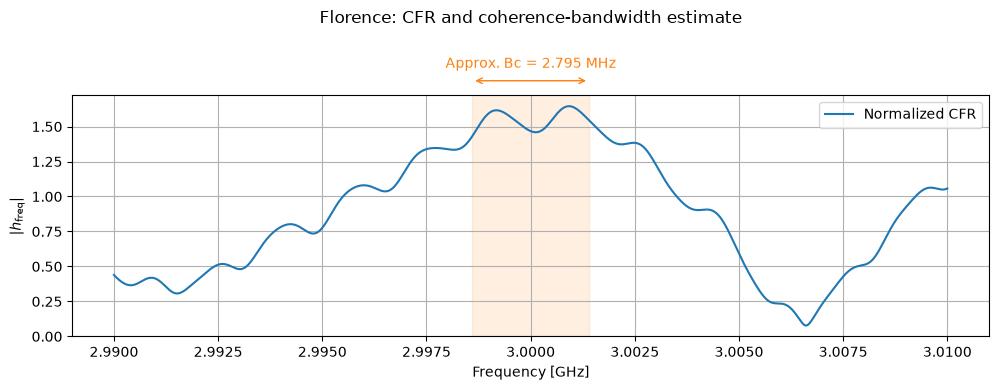

In [99]:
def link_cir(paths_object, link=(0, 0, 0, 0)):
    """Finite, nonzero-power paths for one SISO link at t=0; absolute delays."""
    a_all, tau_all = paths_object.cir(normalize_delays=False, 
                                      num_time_steps=1, 
                                      out_type="numpy")
    rx_i, rx_ant_i, tx_i, tx_ant_i = link
    coefficients = np.asarray(a_all[rx_i, rx_ant_i, tx_i, tx_ant_i, :, 0], dtype=np.complex128)
    
    # RT versions/array modes may share path delays across antenna elements.
    if tau_all.ndim == 5:
        delays = np.asarray(tau_all[rx_i, rx_ant_i, tx_i, tx_ant_i, :],
                            dtype=np.float64)
    elif tau_all.ndim == 3:
        delays = np.asarray(tau_all[rx_i, tx_i, :], dtype=np.float64)
    else:
        raise ValueError(f"Unexpected RT delay shape: {tau_all.shape}")
    
    # Check is power is non-negligible
    power = np.abs(coefficients)**2
    valid = (np.isfinite(delays) & (delays >= 0)
             & np.isfinite(coefficients) & (power > 0))
    if not np.any(valid):
        raise ValueError(f"No finite, nonzero-power propagation paths for link {link}.")
    
    # Reorder and output the CIR amplitude and delays
    order = np.argsort(delays[valid])
    return coefficients[valid][order], delays[valid][order]


def delay_spread_metrics(paths_object, link=(0, 0, 0, 0)):
    """Compute delay spread taking a paths object."""
    # Take CIR removing negligible paths
    coefficients, delays = link_cir(paths_object, link)

    # Compute the formula here
    power = np.abs(coefficients)**2
    weights = power / power.sum()
    excess_delay = delays - delays.min()
    mean_excess_delay = np.sum(weights * excess_delay)
    rms = float(np.sqrt(np.sum(weights * (excess_delay - mean_excess_delay)**2)))
    return {
        "link": link,
        "num_paths": len(delays),
        "first_delay_s": float(delays.min()),
        "mean_excess_delay_s": float(mean_excess_delay),
        "rms_delay_spread_s": rms,
        "max_delay_spread_s": float(np.ptp(delays)),
        "coherence_bandwidth": np.inf if rms == 0 else 1/(rms*5),        
        "coherence_bandwidth_tse": 1 / float(np.ptp(delays)) / 2,
    }


def print_delay_metrics(metrics, label):
    print(f"{label}: link {metrics['link']}, {metrics['num_paths']} valid paths")
    print(f"  RMS delay spread: {metrics['rms_delay_spread_s']*1e9:.3f} ns")
    print(f"  Maximum delay spread (all nonzero-power paths): "
          f"{metrics['max_delay_spread_s']*1e9:.3f} ns")
    print(f"  Approx. Bc: {metrics['coherence_bandwidth']/1e6:.3f} MHz")    


def plot_cfr_with_coherence(paths_object, metrics, center_frequency, 
                            label, sweep_bandwidth=20e6):
    """Show the Bc estimate as an actual-width interval above the CFR."""
    bc = metrics["coherence_bandwidth"]
    # Widen the display if needed so the entire coherence-bandwidth bracket fits.
    span = max(sweep_bandwidth, 1.4*bc) if np.isfinite(bc) else sweep_bandwidth
    offsets = np.linspace(-span/2, span/2, 2048)
    h = paths_object.cfr(frequencies=offsets, normalize=True,
                         normalize_delays=False, out_type="numpy")
    rx_i, rx_ant_i, tx_i, tx_ant_i = metrics["link"]
    magnitude = np.abs(h[rx_i, rx_ant_i, tx_i, tx_ant_i, 0, :])
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.plot((center_frequency + offsets)/1e9, magnitude, label="Normalized CFR")
    if np.isfinite(bc):
        left, right = (center_frequency + np.array([-bc/2, bc/2]))/1e9
        ax.axvspan(left, right, alpha=0.12, color="tab:orange")
        # x in GHz, y in axes coordinates: keep the bracket above the curve.
        transform = ax.get_xaxis_transform()
        ax.annotate("", xy=(left, 1.06), xytext=(right, 1.06),
                    xycoords=transform, textcoords=transform,
                    arrowprops=dict(arrowstyle="<->", color="tab:orange"),
                    annotation_clip=False)
        ax.text((left+right)/2, 1.10, f"Approx. Bc = {bc/1e6:.3f} MHz", 
                transform=transform, ha="center", va="bottom", color="tab:orange")
    else:
        ax.text(0.5, 1.08, "Zero RMS delay spread: estimated Bc is infinite",
                transform=ax.transAxes, ha="center")
    ax.set(xlabel="Frequency [GHz]", ylabel=r"$|h_\mathrm{freq}|$",
           title=f"{label}: CFR and coherence-bandwidth estimate")
    ax.set_title(ax.get_title(), pad=52)
    ax.grid(True)
    ax.legend(loc="best")
    fig.tight_layout()
    plt.show()
    return fig, ax


florence_metrics = delay_spread_metrics(paths)
print_delay_metrics(florence_metrics, "Florence")
_ = plot_cfr_with_coherence(paths, florence_metrics, carrier_frequency, "Florence",
                            sweep_bandwidth=bandwidth)


### Optional: Pisa CIR, CFR, and delay statistics

Run the Pisa scene-loading and path-tracing cells first. The block below is skipped while `paths_pisa` is `None`. As for Florence, it selects the first transmitter/receiver antenna pair and uses absolute delays. The shaded interval and arrow on the CFR show the same $B_{c,50}$ estimate.


In [53]:
pisa_metrics = None
a_pisa, tau_pisa, h_freq_pisa = None, None, None
if scene_pisa is None or paths_pisa is None:
    print("Skipping Pisa channel analysis: configure scene_pisa and compute paths_pisa first.")
else:
    a_pisa, tau_pisa = paths_pisa.cir(normalize_delays=False, out_type="numpy")
    coefficients_pisa, delays_pisa = link_cir(paths_pisa)
    h_freq_pisa = paths_pisa.cfr(frequencies=frequencies, normalize=True,
                                normalize_delays=False, out_type="numpy")
    fig, ax = plt.subplots(figsize=(9, 3))
    ax.stem(delays_pisa*1e9, np.abs(coefficients_pisa))
    ax.set(xlabel=r"$\tau$ [ns]", ylabel=r"$|a|$",
           title="Channel impulse response — Pisa")
    ax.grid(True)
    fig.tight_layout()
    plt.show()
    pisa_metrics = delay_spread_metrics(paths_pisa)
    print_delay_metrics(pisa_metrics, "Pisa")
    _ = plot_cfr_with_coherence(paths_pisa, pisa_metrics, scene_pisa.frequency,
                                "Pisa", sweep_bandwidth=bandwidth)


Skipping Pisa channel analysis: configure scene_pisa and compute paths_pisa first.


## Transmission simulations

We now send **one uncoded block of QAM symbols through the static ray-traced channel in the time domain**, using [Sionna PHY 2.2.0](https://nvlabs.github.io/sionna/phy/), which uses PyTorch. The repository's `sionna==2.2.0` dependency includes PHY; an RT-only installation needs `pip install sionna==2.2.0` as well.

`BinarySource` → `Mapper` → `cir_to_time_channel` / `ApplyTimeChannel` (multipath convolution + AWGN) → single-tap gain correction → hard `Demapper`.

Assumptions for this small teaching example:

- One transmit and one receive antenna: the same link `(0, 0, 0, 0)` used for the statistics. The CIR is frozen at $t=0$; mobility is not simulated here.
- Ideal sinc pulse shaping and matched receive filtering, as assumed by [`cir_to_time_channel`](https://nvlabs.github.io/sionna/phy/api/channel/wireless/sionna.phy.channel.cir_to_time_channel.html). The symbol/sample rate is $B$ symbols/s, with occupied complex-baseband band $[-B/2,B/2]$.
- Perfect timing and knowledge of the strongest sampled channel tap. Only its complex gain is corrected; all the other taps still cause **intersymbol interference (ISI)**. No coding, OFDM, cyclic prefix, channel estimation, or multi-tap equalizer is used.
- We subtract the first path delay **only inside the synchronized transmission model**. This removes bulk propagation latency, preserves the delay spread and ISI, and leaves the absolute-delay CIR/CFR plots above unchanged.
- The discrete channel is normalized to unit tap energy for each bandwidth. QAM has unit average symbol energy. `noise_power` is the **linear variance per complex receive sample**, $E[|w|^2]$, after this normalization (not dBm or a noise spectral density). Keeping it fixed isolates channel dispersion rather than path loss or the change of integrated thermal noise with bandwidth.

`__init__` creates all the Sionna processing blocks. A fixed tap budget lets the same instance test different bandwidths; `__call__` checks that the sampled excess delays fit before it runs. The sinc response is truncated with six samples of margin around the physical delays, with additional unused taps zeroed. The number of symbols and the maximum tap budget can be changed in the constructor.


In [90]:
import torch
from sionna.phy import config as phy_config
from sionna.phy.mapping import BinarySource, Mapper, Demapper
from sionna.phy.channel import cir_to_time_channel, ApplyTimeChannel


class QAMTransmission:
    """One static SISO QAM block with a single-tap receiver, on CPU."""

    def __init__(self, num_symbols=1024, num_bits_per_symbol=4,
                 max_excess_delay_samples=512, seed=42, link=(0, 0, 0, 0)):
        if num_symbols <= 0 or int(num_symbols) != num_symbols:
            raise ValueError("num_symbols must be a positive integer.")
        if (num_bits_per_symbol <= 0 or num_bits_per_symbol % 2
                or int(num_bits_per_symbol) != num_bits_per_symbol):
            raise ValueError("QAM needs a positive even number of bits per symbol.")
        if (max_excess_delay_samples < 0
                or int(max_excess_delay_samples) != max_excess_delay_samples):
            raise ValueError("max_excess_delay_samples must be a nonnegative integer.")
        self.num_symbols = int(num_symbols)
        self.num_bits_per_symbol = int(num_bits_per_symbol)
        self.seed = seed
        self.link = link
        self.l_min = -6
        self.l_max = int(max_excess_delay_samples) + 6
        self.l_tot = self.l_max - self.l_min + 1
        # All processing blocks are instantiated once, not inside __call__.
        self.binary_source = BinarySource(device="cpu")
        self.mapper = Mapper("qam", self.num_bits_per_symbol, device="cpu")
        self.channel = ApplyTimeChannel(self.num_symbols, self.l_tot, device="cpu")
        self.demapper = Demapper("app", constellation=self.mapper.constellation,
                                hard_out=True, device="cpu")

    def __call__(self, bandwidth, snr_db, paths_object):
        bandwidth, snr_db = float(bandwidth), float(snr_db)
        if not np.isfinite(bandwidth) or bandwidth <= 0:
            raise ValueError("bandwidth must be finite and strictly positive, in Hz.")
        if not np.isfinite(snr_db):
            raise ValueError("snr_db must be finite (dB units).")
        coefficients, delays = link_cir(paths_object, self.link)
        delays = delays - delays.min()  # Perfect synchronization to first arrival.
        required_l_max = int(np.ceil(bandwidth*delays.max())) + 6
        if required_l_max > self.l_max:
            raise ValueError(
                f"This bandwidth needs l_max >= {required_l_max}; increase "
                "max_excess_delay_samples when constructing QAMTransmission.")
        
        # Convert snr to noise value        
        noise = torch.tensor(1 / float(sionna.phy.utils.db_to_lin(snr_db)), dtype=torch.float32)        
            

        # RT has no batch dimension; explicitly build a one-link PHY CIR.
        # a: [batch, rx, rx_ant, tx, tx_ant, paths, time]; tau: [batch, rx, tx, paths]
        # Rescale coefficients before float32 conversion; normalization below
        # removes this common scale and avoids underflow for very weak links.
        coefficients = coefficients / np.sqrt(np.sum(np.abs(coefficients)**2))
        a_phy = torch.as_tensor(coefficients, dtype=torch.complex64).reshape(1, 1, 1, 1, 1, -1, 1)
        tau_phy = torch.as_tensor(delays, dtype=torch.float32).reshape(1, 1, 1, -1)
        h = cir_to_time_channel(bandwidth, a_phy, tau_phy, l_min=self.l_min, l_max=self.l_max, normalize=False)
        
        # Six-sample right-hand sinc margin, followed by unused zero taps.
        active_taps = required_l_max - self.l_min + 1
        h[..., active_taps:] = 0
        tap_energy = h.abs().square().sum()
        if not torch.isfinite(tap_energy) or tap_energy <= 0:
            raise ValueError("The sampled channel has zero/nonfinite energy.")
        h = h / torch.sqrt(tap_energy)
        taps_siso = h.reshape(-1)
        peak_index = int(torch.argmax(taps_siso.abs().square()).item())
        gain = taps_siso[peak_index]

        # Reuse the same bits/noise seed for a fair comparison of bandwidths.
        phy_config.seed = self.seed
        
        # Generate random bits
        bits = self.binary_source([1, 1, 1, self.num_symbols*self.num_bits_per_symbol])
        # Map bits to QAM symbols
        symbols = self.mapper(bits)
        
        # ApplyTimeChannel expects a channel sample for every output sample.
        h_time = h.expand(1, 1, 1, 1, 1, self.num_symbols + self.l_tot - 1, self.l_tot)
        

        # Apply channel over transmitted bit
        received = self.channel(symbols, h_time, noise)
        # Array index 0 represents physical lag l_min. Align to the peak tap.
        aligned = received[..., peak_index:peak_index + self.num_symbols]
        equalized = aligned / gain
        effective_noise = noise / gain.abs().square()
        # The floor only keeps the demapper well-defined in a noiseless test.
        bits_hat = self.demapper(equalized, effective_noise.clamp_min(1e-12))
        b = bits.detach().cpu().numpy().reshape(-1).astype(np.int32)
        b_hat = bits_hat.detach().cpu().numpy().reshape(-1).astype(np.int32)
        errors = int(np.count_nonzero(b != b_hat))
        isi_energy = float((taps_siso.abs().square().sum() - gain.abs().square()).item())
        return {
            "bandwidth_hz": bandwidth, "noise_power": noise_power,
            "bits": b, "bits_hat": b_hat,
            "symbols": symbols.detach().cpu().numpy().reshape(-1),
            "received_symbols": equalized.detach().cpu().numpy().reshape(-1),
            "received_samples": received.detach().cpu().numpy().reshape(-1),
            "taps": taps_siso.detach().cpu().numpy(),
            "tap_lags": np.arange(self.l_min, self.l_max + 1),
            "peak_lag": self.l_min + peak_index,
            "isi_to_main_power": isi_energy / float(gain.abs().square().item()),
            "num_errors": errors, "ber": errors / len(b),
        }


### Compare a narrow band with a band wider than the coherence estimate

The same class instance sends the same **4096-bit, 16-QAM block** through the same Florence paths with $B=0.1B_c$ and $B=10B_c$. A normalized noise power of $10^{-3}$ corresponds to a nominal $E_s/N_0$ of 30 dB before accounting for ISI and peak-tap gain. Only the symbol rate and sampled multipath response change.

Each plot shows the **first 100 transmitted and hard-decided received bits**, with errors marked in red. The BER printed in the title is computed over the entire block. Bit index is used so the streams can be compared directly; the simulated block duration is also printed. These are two single-block demonstrations, not Monte Carlo BER estimates. A wide band can still work well for a dominant-path channel: exceeding the heuristic $B_c$ does not guarantee bit errors.


In [98]:
# Simulate each bandwidth once; reuse these results in both plots below.
transmission = QAMTransmission(num_symbols=1024, num_bits_per_symbol=4)
coherence_bandwidth = florence_metrics["coherence_bandwidth"]
snr_db =  30  # SNR after channel normalization
transmission_results = {}

if not np.isfinite(coherence_bandwidth) or coherence_bandwidth <= 0:
    print("No finite positive coherence-bandwidth estimate: the two B/Bc cases "
          "are undefined. Choose a multipath link with nonzero RMS delay spread.")
else:
    cases = [("a) Narrow band", 0.1*coherence_bandwidth),
             ("b) Wider than coherence bandwidth", 10*coherence_bandwidth)]
    for label, transmission_bandwidth in cases:
        transmission_results[label] = transmission(transmission_bandwidth, snr_db, paths)


### Received symbols on the constellation plane

Before inspecting the bit decisions, compare all 1024 received symbols with the ideal normalized 16-QAM constellation. The points shown are the samples **after timing alignment and single-tap complex-gain correction, before hard demapping**. Both panels use the same axis limits and equal I/Q scaling. A wider cloud shows residual noise and intersymbol interference; these are the same realizations used in the bit-stream plots below.

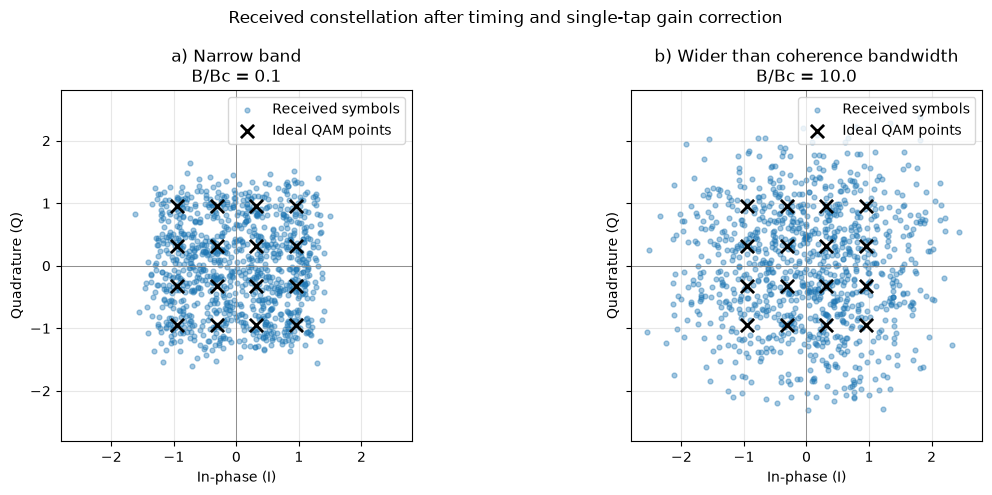

In [95]:
# Get the exact normalized reference constellation used by the Sionna mapper.
ideal_points = transmission.mapper.constellation().detach().cpu().numpy().reshape(-1)
all_points = np.concatenate([ideal_points] + [result["received_symbols"] for result in transmission_results.values()])
axis_limit = 1.1 * max(np.max(np.abs(all_points.real)),
                       np.max(np.abs(all_points.imag)), 1.0)


# Generate two plots for the I/Q results of the different bandwidths
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
for ax, (label, result) in zip(axes, transmission_results.items()):
    received_symbols = result["received_symbols"]
    ax.scatter(received_symbols.real, received_symbols.imag,
               s=12, alpha=0.4, color="tab:blue", label="Received symbols")
    ax.scatter(ideal_points.real, ideal_points.imag, s=90, marker="x",
               linewidths=2, color="black", label="Ideal QAM points", zorder=3)
    ax.axhline(0, color="gray", linewidth=0.6)
    ax.axvline(0, color="gray", linewidth=0.6)
    ax.set(xlim=(-axis_limit, axis_limit), ylim=(-axis_limit, axis_limit),
           xlabel="In-phase (I)", ylabel="Quadrature (Q)",
           title=f"{label}\nB/Bc = {result['bandwidth_hz']/coherence_bandwidth:.1f}")
    ax.set_aspect("equal", adjustable="box")
    ax.grid(True, alpha=0.3)
    ax.legend(loc="upper right")
fig.suptitle("Received constellation after timing and single-tap gain correction")
fig.tight_layout()
plt.show()


### Transmission results: transmitted and received bits

These plots reuse the same simulated blocks shown in the constellation plots above.

a) Narrow band: B = 0.279 MHz, B/Bc = 0.1, duration = 3663.97 us
  259/4096 bit errors; BER = 0.06323; ISI/main-tap power = 4.268e-05
b) Wider than coherence bandwidth: B = 27.948 MHz, B/Bc = 10.0, duration = 36.64 us
  1115/4096 bit errors; BER = 0.2722; ISI/main-tap power = 0.6095


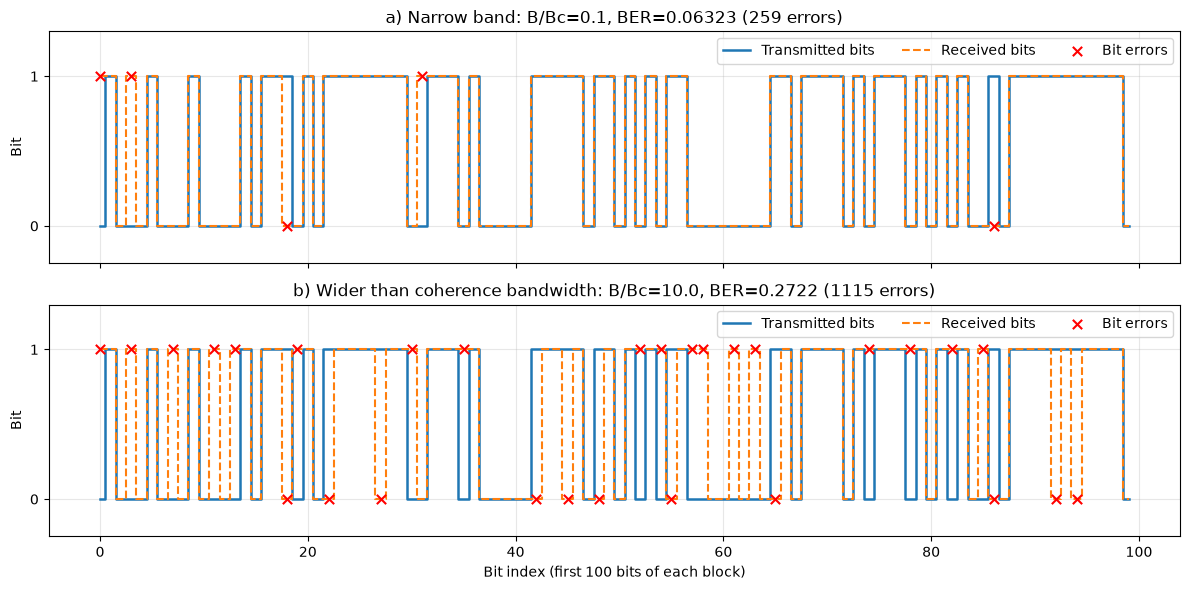

In [97]:
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
for ax, (label, result) in zip(axes, transmission_results.items()):
    transmission_bandwidth = result["bandwidth_hz"]
    print(f"{label}: B = {transmission_bandwidth/1e6:.3f} MHz, "
          f"B/Bc = {transmission_bandwidth/coherence_bandwidth:.1f}, "
          f"duration = {transmission.num_symbols/transmission_bandwidth*1e6:.2f} us")
    print(f"  {result['num_errors']}/{len(result['bits'])} bit errors; "
          f"BER = {result['ber']:.4g}; "
          f"ISI/main-tap power = {result['isi_to_main_power']:.4g}")
    count = min(100, len(result["bits"]))
    indices = np.arange(count)
    sent = result["bits"][:count]
    detected = result["bits_hat"][:count]
    wrong = sent != detected
    ax.step(indices, sent, where="mid", label="Transmitted bits", linewidth=1.8)
    ax.step(indices, detected, where="mid", label="Received bits", linestyle="--")
    ax.scatter(indices[wrong], detected[wrong], color="red", marker="x",
               s=45, label="Bit errors", zorder=3)
    ax.set(yticks=[0, 1], ylim=(-0.25, 1.3), ylabel="Bit",
           title=f"{label}: B/Bc={transmission_bandwidth/coherence_bandwidth:.1f}, "
                 f"BER={result['ber']:.4g} ({result['num_errors']} errors)")
    ax.grid(True, alpha=0.3)
    ax.legend(loc="upper right", ncol=3)
axes[-1].set_xlabel("Bit index (first 100 bits of each block)")
fig.tight_layout()
plt.show()


## Summary

In this tutorial, you have learned the basics of Sionna RT. You now know how paths can be found in complex environments
and how the CIR, CFR, and taps can be derived from them, including static and Doppler-based time evolution. You have also measured RMS and maximum delay spreads, estimated coherence bandwidth, and simulated uncoded QAM transmission below and above that estimate.

There is one key feature of Sionna RT that was not discussed in this notebook: Automatic gradient computation.
Like most components of Sionna, also Sionna RT is differentiable with respect to most parameters, such as radio materials, scattering and atenna patterns, transmitter and receiver orientations, array geometries, positions, etc.

Please have a look at the [API documentation](https://nvlabs.github.io/sionna/rt/api/rt.html) of the various components and the other available [Tutorials](https://nvlabs.github.io/sionna/rt/tutorials.html) and [Developer Guides](https://nvlabs.github.io/sionna/rt/developer/developer.html).